NOTEBOOK 05 — MODEL COMPARISON
TensorFlow version: 2.22.0-rc0

Project root:
C:\Users\24105A2006\Desktop\Tumor_Detection\Tumor_Detection

Training directory:
C:\Users\24105A2006\Desktop\Tumor_Detection\Tumor_Detection\data\raw\Training

Testing directory:
C:\Users\24105A2006\Desktop\Tumor_Detection\Tumor_Detection\data\raw\Testing

Classes:
0: glioma
1: meningioma
2: notumor
3: pituitary

Loading test dataset...
Found 1600 files belonging to 4 classes.
Test dataset loaded.

Number of test images: 1600

MODEL FILES
[FOUND] CNN:
        C:\Users\24105A2006\Desktop\Tumor_Detection\Tumor_Detection\models\cnn\best_cnn.keras
[FOUND] VGG16:
        C:\Users\24105A2006\Desktop\Tumor_Detection\Tumor_Detection\models\vgg16\best_vgg16.keras
[FOUND] ResNet50:
        C:\Users\24105A2006\Desktop\Tumor_Detection\Tumor_Detection\models\resnet50\best_resnet50.keras
[FOUND] MobileNetV2:
        C:\Users\24105A2006\Desktop\Tumor_Detection\Tumor_Detection\models\mobilenetv2\best_mobilenetv2.keras

EVALUA

,Model,Accuracy,Precision,Recall,F1 Score
0,ResNet50,0.9331,0.9361,0.9331,0.9316
1,VGG16,0.8988,0.9019,0.8988,0.8964
2,MobileNetV2,0.8856,0.8917,0.8856,0.8825
3,CNN,0.7581,0.7674,0.7581,0.7456



Comparison saved to:
C:\Users\24105A2006\Desktop\Tumor_Detection\Tumor_Detection\results\model_comparison.csv


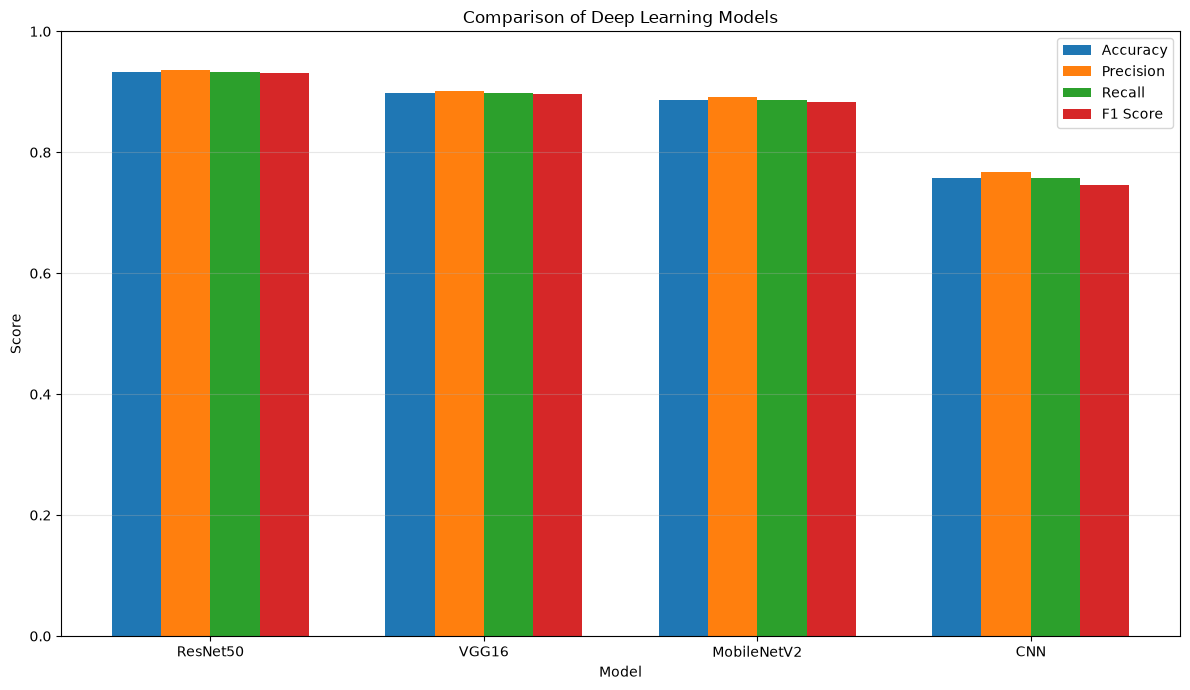


Comparison figure saved to:
C:\Users\24105A2006\Desktop\Tumor_Detection\Tumor_Detection\results\figures\model_comparison.png

CONFUSION MATRICES


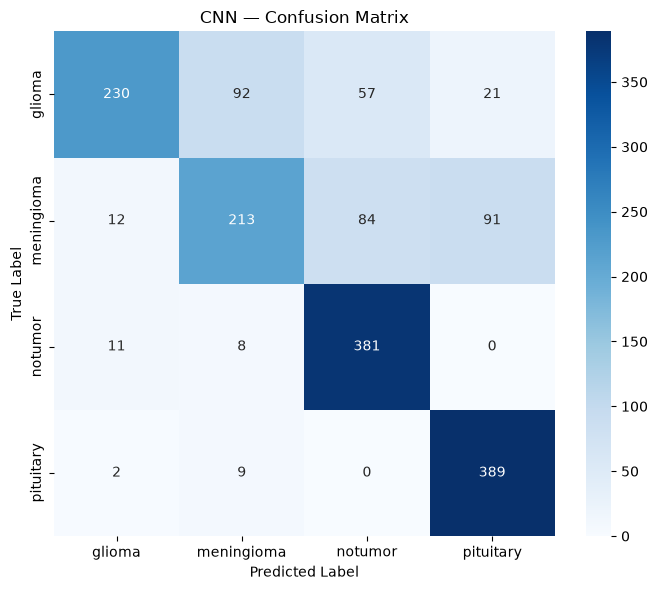

CNN confusion matrix saved:
C:\Users\24105A2006\Desktop\Tumor_Detection\Tumor_Detection\results\figures\cnn_confusion_matrix.png


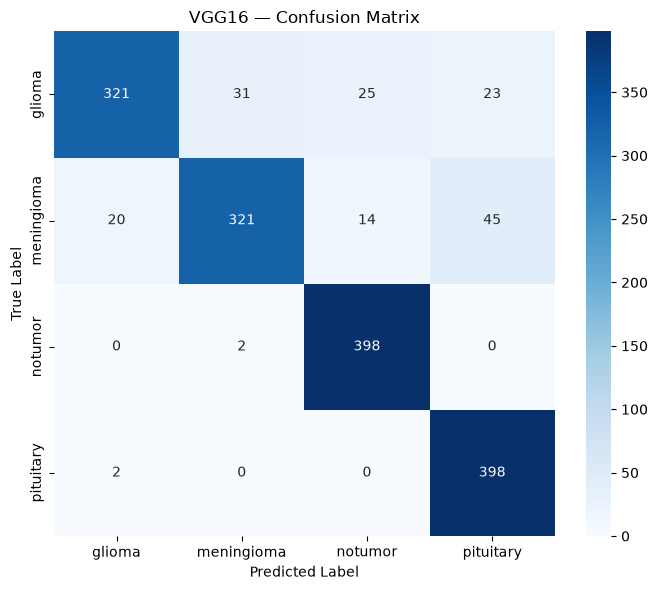

VGG16 confusion matrix saved:
C:\Users\24105A2006\Desktop\Tumor_Detection\Tumor_Detection\results\figures\vgg16_confusion_matrix.png


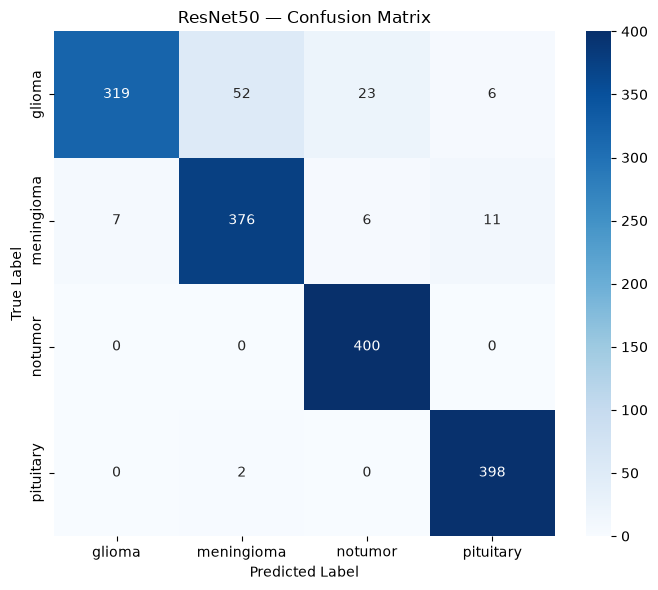

ResNet50 confusion matrix saved:
C:\Users\24105A2006\Desktop\Tumor_Detection\Tumor_Detection\results\figures\resnet50_confusion_matrix.png


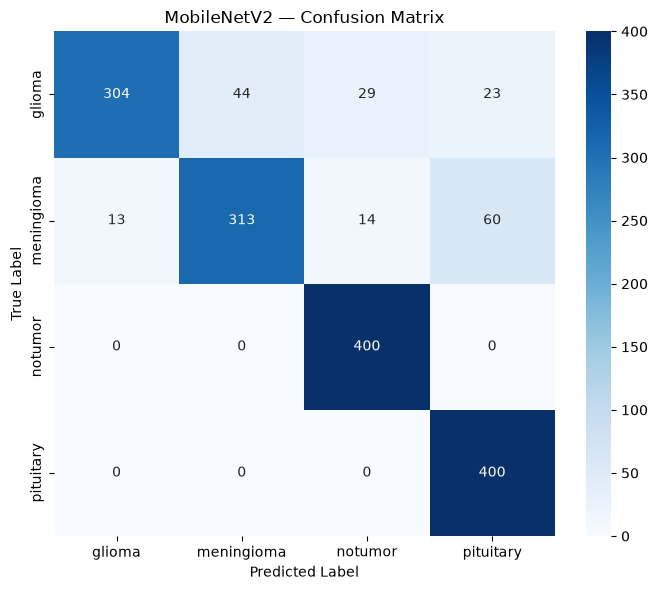

MobileNetV2 confusion matrix saved:
C:\Users\24105A2006\Desktop\Tumor_Detection\Tumor_Detection\results\figures\mobilenetv2_confusion_matrix.png

BEST MODEL
Model     : ResNet50
Accuracy  : 0.9331
Precision : 0.9361
Recall    : 0.9331
F1 Score  : 0.9316

Best model information saved to:
C:\Users\24105A2006\Desktop\Tumor_Detection\Tumor_Detection\results\best_model.csv

CLASSIFICATION REPORTS


CNN
              precision    recall  f1-score   support

      glioma       0.90      0.57      0.70       400
  meningioma       0.66      0.53      0.59       400
     notumor       0.73      0.95      0.83       400
   pituitary       0.78      0.97      0.86       400

    accuracy                           0.76      1600
   macro avg       0.77      0.76      0.75      1600
weighted avg       0.77      0.76      0.75      1600



VGG16
              precision    recall  f1-score   support

      glioma       0.94      0.80      0.86       400
  meningioma       0.91      0.80      0.85    

In [ ]:
#  MODEL COMPARISON

import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("=" * 70)
print("NOTEBOOK 05 — MODEL COMPARISON")
print("=" * 70)

# SETTINGS


IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

tf.random.set_seed(SEED)
np.random.seed(SEED)

print("TensorFlow version:", tf.__version__)

# FIND PROJECT ROOT

current_path = Path.cwd().resolve()

project_root = None

for path in [current_path] + list(current_path.parents):
    if (path / "data" / "raw").exists():
        project_root = path
        break

if project_root is None:
    raise FileNotFoundError(
        "Could not find project root containing data/raw.\n"
        "Make sure you are running this notebook inside the project."
    )

print("\nProject root:")
print(project_root)

# FIND TRAINING / TESTING FOLDERS

raw_dir = project_root / "data" / "raw"

training_dirs = list(raw_dir.rglob("Training"))
testing_dirs = list(raw_dir.rglob("Testing"))

if not training_dirs:
    raise FileNotFoundError("Training folder not found.")

if not testing_dirs:
    raise FileNotFoundError("Testing folder not found.")

train_dir = training_dirs[0]
test_dir = testing_dirs[0]

print("\nTraining directory:")
print(train_dir)

print("\nTesting directory:")
print(test_dir)

# DETECT CLASS NAMES

class_names = sorted([
    folder.name
    for folder in train_dir.iterdir()
    if folder.is_dir()
])

if len(class_names) != 4:
    raise ValueError(
        f"Expected 4 classes, but found {len(class_names)}: {class_names}"
    )

print("\nClasses:")
for i, name in enumerate(class_names):
    print(f"{i}: {name}")

# LOAD TEST DATASET

print("\nLoading test dataset...")

test_dataset = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    labels="inferred",
    label_mode="categorical",
    class_names=class_names,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
    seed=SEED
)

# Improve performance
AUTOTUNE = tf.data.AUTOTUNE

test_dataset = test_dataset.prefetch(AUTOTUNE)

print("Test dataset loaded.")

# GET TRUE LABELS

y_true = []

for images, labels in test_dataset:
    y_true.extend(np.argmax(labels.numpy(), axis=1))

y_true = np.array(y_true)

print("\nNumber of test images:", len(y_true))

# DEFINE SERIALIZABLE PREPROCESSING LAYERS
# These are required because Notebook 04 used custom preprocessing
# layers instead of Lambda layers.

@tf.keras.utils.register_keras_serializable()
class VGG16Preprocess(tf.keras.layers.Layer):

    def call(self, inputs):
        return tf.keras.applications.vgg16.preprocess_input(inputs)


@tf.keras.utils.register_keras_serializable()
class ResNet50Preprocess(tf.keras.layers.Layer):

    def call(self, inputs):
        return tf.keras.applications.resnet50.preprocess_input(inputs)


@tf.keras.utils.register_keras_serializable()
class MobileNetV2Preprocess(tf.keras.layers.Layer):

    def call(self, inputs):
        return tf.keras.applications.mobilenet_v2.preprocess_input(inputs)


custom_objects = {
    "VGG16Preprocess": VGG16Preprocess,
    "ResNet50Preprocess": ResNet50Preprocess,
    "MobileNetV2Preprocess": MobileNetV2Preprocess
}

# LOCATE MODEL FILES


model_paths = {
    "CNN": [
        project_root / "models" / "cnn" / "best_cnn_improved.keras",
        project_root / "models" / "cnn" / "best_cnn.keras"
    ],

    "VGG16": [
        project_root / "models" / "vgg16" / "best_vgg16.keras"
    ],

    "ResNet50": [
        project_root / "models" / "resnet50" / "best_resnet50.keras"
    ],

    "MobileNetV2": [
        project_root / "models" / "mobilenetv2" / "best_mobilenetv2.keras"
    ]
}

# Select first existing file
selected_models = {}

print("\n" + "=" * 70)
print("MODEL FILES")
print("=" * 70)

for model_name, paths in model_paths.items():

    found = None

    for path in paths:
        if path.exists():
            found = path
            break

    if found is not None:
        selected_models[model_name] = found
        print(f"[FOUND] {model_name}:")
        print(f"        {found}")

    else:
        print(f"[MISSING] {model_name}")
        print("          Model will be skipped.")

#  RESULTS STORAGE

results = []

classification_reports = {}

confusion_matrices = {}

loaded_models = {}

#  EVALUATE EACH MODEL


for model_name, model_path in selected_models.items():

    print("\n" + "=" * 70)
    print(f"EVALUATING: {model_name}")
    print("=" * 70)

    try:

        # --------------------------------------------------------
        # Load model
        # --------------------------------------------------------

        print("Loading model...")

        model = tf.keras.models.load_model(
            model_path,
            custom_objects=custom_objects,
            compile=False
        )

        loaded_models[model_name] = model

        print("Model loaded successfully.")

        # --------------------------------------------------------
        # Prediction
        # --------------------------------------------------------

        print("Generating predictions...")

        y_probability = model.predict(
            test_dataset,
            verbose=1
        )

        y_pred = np.argmax(
            y_probability,
            axis=1
        )

        # --------------------------------------------------------
        # Metrics
        # --------------------------------------------------------

        accuracy = accuracy_score(
            y_true,
            y_pred
        )

        precision = precision_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        )

        recall = recall_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        )

        f1 = f1_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        )

        # --------------------------------------------------------
        # Store results
        # --------------------------------------------------------

        results.append({
            "Model": model_name,
            "Accuracy": accuracy,
            "Precision": precision,
            "Recall": recall,
            "F1 Score": f1
        })

        # --------------------------------------------------------
        # Classification report
        # --------------------------------------------------------

        report = classification_report(
            y_true,
            y_pred,
            target_names=class_names,
            zero_division=0
        )

        classification_reports[model_name] = report

        # --------------------------------------------------------
        # Confusion matrix
        # --------------------------------------------------------

        cm = confusion_matrix(
            y_true,
            y_pred
        )

        confusion_matrices[model_name] = cm

        # --------------------------------------------------------
        # Print metrics
        # --------------------------------------------------------

        print("\n" + "-" * 50)
        print(f"{model_name} RESULTS")
        print("-" * 50)

        print(f"Accuracy : {accuracy:.4f}")
        print(f"Precision: {precision:.4f}")
        print(f"Recall   : {recall:.4f}")
        print(f"F1 Score : {f1:.4f}")

        print("\nClassification Report:")
        print(report)

    except Exception as e:

        print(f"\nERROR evaluating {model_name}")
        print(type(e).__name__)
        print(e)

# CREATE COMPARISON DATAFRAME


if not results:
    raise RuntimeError(
        "No models were successfully evaluated.\n"
        "Check that your trained .keras model files exist."
    )

comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 70)
print("FINAL MODEL COMPARISON")
print("=" * 70)

display(
    comparison_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}"
    })
)

# SAVE COMPARISON CSV

results_dir = project_root / "results"
figures_dir = results_dir / "figures"

results_dir.mkdir(
    parents=True,
    exist_ok=True
)

figures_dir.mkdir(
    parents=True,
    exist_ok=True
)

comparison_csv = results_dir / "model_comparison.csv"

comparison_df.to_csv(
    comparison_csv,
    index=False
)

print("\nComparison saved to:")
print(comparison_csv)

# BAR CHART — MODEL COMPARISON


plt.figure(figsize=(12, 7))

metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score"
]

x = np.arange(len(comparison_df))
width = 0.18

for i, metric in enumerate(metric_columns):

    plt.bar(
        x + (i - 1.5) * width,
        comparison_df[metric],
        width,
        label=metric
    )

plt.xticks(
    x,
    comparison_df["Model"]
)

plt.ylim(0, 1.0)

plt.ylabel("Score")

plt.xlabel("Model")

plt.title(
    "Comparison of Deep Learning Models"
)

plt.legend()

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

comparison_figure = figures_dir / "model_comparison.png"

plt.savefig(
    comparison_figure,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nComparison figure saved to:")
print(comparison_figure)

#  CONFUSION MATRICES


print("\n" + "=" * 70)
print("CONFUSION MATRICES")
print("=" * 70)

for model_name, cm in confusion_matrices.items():

    plt.figure(figsize=(7, 6))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")

    plt.title(
        f"{model_name} — Confusion Matrix"
    )

    plt.tight_layout()

    cm_path = (
        figures_dir /
        f"{model_name.lower()}_confusion_matrix.png"
    )

    plt.savefig(
        cm_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print(f"{model_name} confusion matrix saved:")
    print(cm_path)

#  FIND BEST MODEL

best_row = comparison_df.iloc[0]

best_model_name = best_row["Model"]
best_accuracy = best_row["Accuracy"]

print("\n" + "=" * 70)
print("BEST MODEL")
print("=" * 70)

print(f"Model     : {best_model_name}")
print(f"Accuracy  : {best_row['Accuracy']:.4f}")
print(f"Precision : {best_row['Precision']:.4f}")
print(f"Recall    : {best_row['Recall']:.4f}")
print(f"F1 Score  : {best_row['F1 Score']:.4f}")

# SAVE BEST MODEL INFORMATION

best_model_info = pd.DataFrame([{
    "Best Model": best_model_name,
    "Accuracy": best_row["Accuracy"],
    "Precision": best_row["Precision"],
    "Recall": best_row["Recall"],
    "F1 Score": best_row["F1 Score"]
}])

best_model_info_path = results_dir / "best_model.csv"

best_model_info.to_csv(
    best_model_info_path,
    index=False
)

print("\nBest model information saved to:")
print(best_model_info_path)

# PRINT ALL CLASSIFICATION REPORTS


print("\n" + "=" * 70)
print("CLASSIFICATION REPORTS")
print("=" * 70)

for model_name, report in classification_reports.items():

    print("\n")
    print("=" * 60)
    print(model_name)
    print("=" * 60)
    print(report)

# FINAL SUMMARY

print("\n" + "=" * 70)
print("NOTEBOOK 05 COMPLETE")
print("=" * 70)

print("\nModels successfully evaluated:")

for model_name in comparison_df["Model"]:
    print(f"  ✓ {model_name}")

print("\nBest model:")
print(f"  {best_model_name}")

print(f"\nBest accuracy: {best_accuracy * 100:.2f}%")

print("\nOutput files:")
print(f"  ✓ {comparison_csv}")
print(f"  ✓ {comparison_figure}")
print(f"  ✓ {best_model_info_path}")

print("\nConfusion matrices:")
for model_name in confusion_matrices:
    print(
        f"  ✓ {figures_dir / f'{model_name.lower()}_confusion_matrix.png'}"
    )

print("\n" + "=" * 70)